# **Banking Customer Churn & Retention Analysis**


In banking, churn could mean:

*   A customer closing their bank account.

*   A customer moving their banking relationship elsewhere.
*   A customer becoming inactive, depending on the bank's definition.


For this project, I'll use the churn indicator supplied in the dataset.

The main business objective is to determine which customer characteristics are associated with higher churn and recommend ways the bank could improve retention.



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os

# Download the dataset directory
dataset_path = kagglehub.dataset_download("saurabhbadole/bank-customer-churn-prediction-dataset")

# List files in the downloaded directory to find the exact CSV filename
print("Files in dataset:", os.listdir(dataset_path))

# Assuming the file is named something like 'Churn_Modelling.csv' or similar (replace with your actual filename from the printout)
# If it's directly inside, you can join the path like this:
csv_file_path = os.path.join(dataset_path, "Churn_Modelling.csv") # Update filename if needed

df = pd.read_csv(csv_file_path)
df.head()

100%|██████████| 262k/262k [00:00<00:00, 41.4MB/s]

Extracting files...
Files in dataset: ['Churn_Modelling.csv']


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [3]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [4]:
df['CustomerId'].duplicated().value_counts()

,count
CustomerId,
False,10000


In [5]:
df_clean = df.drop(
    columns=["RowNumber"],
    errors="ignore"
)

In [6]:
df_clean["AgeRange"] = pd.cut(
    df_clean["Age"],
    bins=[0, 25, 35, 45, 55, 100],
    labels=["Under 25", "25-34", "35-44",
            "45-54", "55+"],
    right=False
)

In [7]:
df_clean.head()

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,AgeRange
0,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,35-44
1,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,35-44
2,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,35-44
3,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,35-44
4,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,35-44


In [8]:
df_clean['ChurnStatus'] = df_clean["Exited"].map({
    0: "Retained",
    1: "Churned"
})
df_clean.head()

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,AgeRange,ChurnStatus
0,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,35-44,Churned
1,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,35-44,Retained
2,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,35-44,Churned
3,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,35-44,Retained
4,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,35-44,Retained


In [9]:
df_clean.to_csv(
    "cleaned_bank_customer_churn.csv",
    index=False
)

## **Exploratory Data Analysis**

In [10]:
#Analysis 1: Overall customer churn
# Calculate the churn rate

churn_rate = df_clean["Exited"].mean() * 100
print(f"Churn Rate: {churn_rate:.2f}%")

Churn Rate: 20.37%


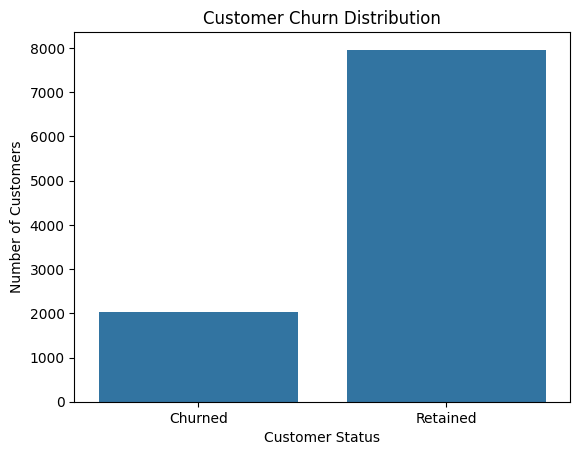

In [11]:
#visualizing the churn and retained customers

sns.countplot(data=df_clean, x="ChurnStatus")

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")

plt.show()

**Questions:**

**How many customers have churned?** Around 2000

**How many are retained?** Almost around 8000

**Is churn a significant business concern?** Yes, out of 10000 customers, about 1/5 have churned which is a matter of concern

In [12]:
# Analysis 2: Churn by Age group
age_churn=df_clean.groupby("AgeRange")["Exited"].mean()*100
age_churn

/tmp/ipykernel_2990/1584789200.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_churn=df_clean.groupby("AgeRange")["Exited"].mean()*100


,Exited
AgeRange,
Under 25,8.752735
25-34,7.759156
35-44,17.658880
45-54,48.148148
55+,38.775510


<Axes: xlabel='AgeRange'>

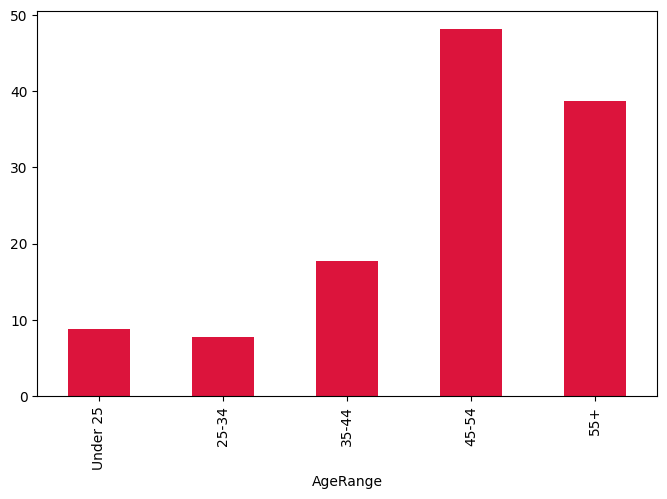

In [13]:
# Extract only Exited == 1 percentages and plot
age_churn.plot(
    kind="bar", color="crimson", figsize=(8, 5)
)

**Questions:**

**Which age group has the highest churn rate?**
45-54 year old

**Are older customers more likely to leave?**
Yes

**Which customer segment should the bank investigate further?**
Most likely people above 44 years of age should be investigated for churn analysis

In [14]:
#Analysis 3: Churn by geography
geo_churn=df_clean.groupby("Geography")["Exited"].mean()*100
geo_churn

,Exited
Geography,
France,16.154767
Germany,32.443204
Spain,16.673395


<Axes: xlabel='Geography'>

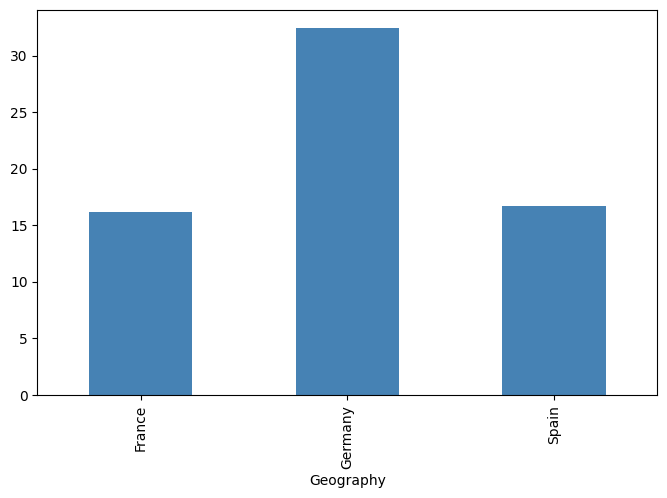

In [15]:
# Extract only Exited == 1 percentages and plot
geo_churn.plot(
    kind="bar", color="steelblue", figsize=(8, 5)
)

In [16]:
#Analysis 4: Churn by activity status
activity_churn = df_clean.groupby(
    "IsActiveMember"
)["Exited"].mean() * 100

print(activity_churn)

IsActiveMember
0    26.850897
1    14.269074
Name: Exited, dtype: float64


**Questions:**

Are inactive customers more likely to churn? The customers who are inactive are more likely to churn

Does customer engagement appear related to retention? Yes, based on the results, customer engagement is heavily related to retention.

In [17]:
#Analysis 5: Churn by number of products
product_churn = df_clean.groupby(
    "NumOfProducts"
)["Exited"].mean() * 100

print(product_churn)

NumOfProducts
1     27.714398
2      7.581699
3     82.706767
4    100.000000
Name: Exited, dtype: float64


**Questions:**

**Are customers with one product more likely to
leave?**

Yes. Customers with 1 product have a 27.71% churn rate. While this is lower than the extreme spikes seen at 3 or 4 products, it is still notably high (meaning over 1 out of every 4 single-product customers leaves). Because they only hold a single product, they have very low "stickiness" or integration with the bank, making it easy for them to take their business elsewhere.

**Does having multiple banking products relate to retention?**

Yes, but it depends heavily on how many products they have. The data reveals a very clear U-shaped relationship:

**The Sweet Spot (2 Products):** Having 2 products is the absolute best scenario for retention, with the churn rate dropping dramatically to just 7.58%. This indicates that holding two products creates a healthy level of engagement and loyalty without overwhelming the customer.

**The Over-Saturation Risk (3 & 4 Products):** Retention collapses completely as product counts climb past two. Churn skyrockets to 82.71% for 3 products and hits 100% for 4 products. This suggests that customers holding 3 or more products are likely facing issues like complex fee structures, aggressive or misaligned cross-selling, or unmanageable bundled accounts that drive them away entirely.

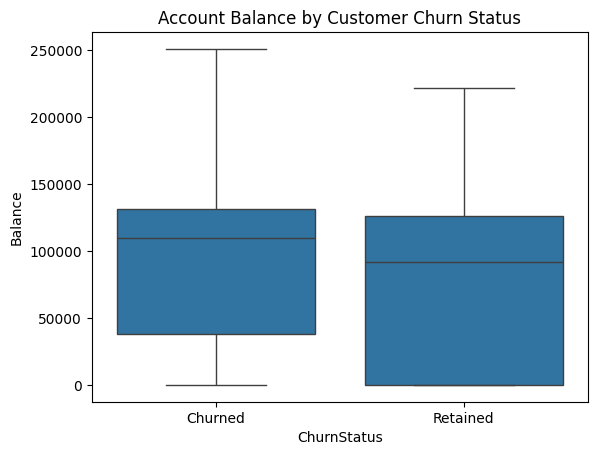

In [18]:
#Analysis 6: Account balance and churn

sns.boxplot(
    data=df_clean,
    x="ChurnStatus",
    y="Balance"
)

plt.title("Account Balance by Customer Churn Status")
plt.show()